# Atividade Prática Final — Inteligência Artificial

**Tema:** Descoberta de padrões e classificação de dígitos manuscritos com K-Means e redes neurais

**Aluno:** Rafael de Moura Paz  
**Professor:** Aldir Silva Sousa

---

## Tarefa 1 — Preparação e exploração dos dados

### 1.1 Carregamento e exploração do Digits

O conjunto


Dimensão de X (atributos): (1797, 64)
Dimensão de y (rótulos): (1797,)
Cada imagem: (8, 8) pixels

Distribuição das classes:
Dígito 0: 178 imagens
Dígito 1: 182 imagens
Dígito 2: 177 imagens
Dígito 3: 183 imagens
Dígito 4: 181 imagens
Dígito 5: 182 imagens
Dígito 6: 181 imagens
Dígito 7: 179 imagens
Dígito 8: 174 imagens
Dígito 9: 180 imagens


Text(0, 0.5, 'Quantidade')

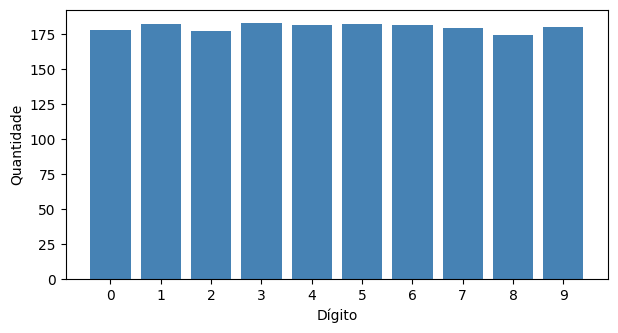

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# Carregar o Digits
digits = load_digits()
X, y = digits.data, digits.target

# Dimensão dos atributos
print("Dimensão de X (atributos):", X.shape)
print("Dimensão de y (rótulos):", y.shape)
print("Cada imagem:", digits.images[0].shape, "pixels")

# Distribuição das 10 classes
classes, contagens = np.unique(y, return_counts=True)
print("\nDistribuição das classes:")
for c, n in zip(classes, contagens):
    print(f"Dígito {c}: {n} imagens")

plt.figure(figsize=(7, 3.5))
plt.bar(classes, contagens, color="steelblue")
plt.xticks(classes)
plt.xlabel("Dígito"); plt.ylabel("Quantidade")

### 1.2 Divisão em treino, validação e teste

Os dados são divididos em duas etapas, sempre com **estratificação** (`stratify`), para manter a mesma proporção de cada dígito em todas as partes:

1. **80% treino + validação** e **20% teste**. O teste fica guardado e só é usado na avaliação final dos modelos.
2. Da parte de treino, separamos **20% para validação**. Assim a validação sai **exclusivamente do treino** e o teste não participa de nenhuma decisão ou ajuste.

Usamos `random_state=42` para que a divisão seja sempre a mesma em todas as tarefas.

Tamanho

In [3]:
import random
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# 80% treino+validação / 20% teste, estratificado
X_trainval, X_te, y_trainval, y_te = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# validação extraída SOMENTE da parcela de treino (20% dela)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=SEED)

print("Total:    ", X.shape)
print("Treino:   ", X_tr.shape)
print("Validação:", X_val.shape)
print("Teste:    ", X_te.shape)

# Conferindo a estratificação: proporção (%) de cada dígito em cada parte
print("\nDígito | Treino | Validação | Teste")
for d in range(10):
    p_tr = 100 * np.mean(y_tr == d)
    p_val = 100 * np.mean(y_val == d)
    p_te = 100 * np.mean(y_te == d)
    print(f"  {d}    | {p_tr:5.2f}% |  {p_val:5.2f}%   | {p_te:5.2f}%")

Total:     (1797, 64)
Treino:    (1149, 64)
Validação: (288, 64)
Teste:     (360, 64)

Dígito | Treino | Validação | Teste
  0    |  9.83% |  10.07%   | 10.00%
  1    | 10.18% |  10.07%   | 10.00%
  2    |  9.92% |   9.72%   |  9.72%
  3    | 10.18% |  10.07%   | 10.28%
  4    | 10.10% |  10.07%   | 10.00%
  5    | 10.10% |  10.07%   | 10.28%
  6    | 10.10% |  10.07%   | 10.00%
  7    |  9.92% |  10.07%   | 10.00%
  8    |  9.66% |   9.72%   |  9.72%
  9    | 10.01% |  10.07%   | 10.00%


### 1.3 Padronização dos atributos

Usamos o `StandardScaler`, que deixa cada pixel com **média 0 e desvio padrão 1**. Isso é importante porque o K-Means usa distância euclidiana e as redes neurais treinam melhor com atributos na mesma escala.

**Por que ajustar só no treino?**
O escalonador é ajustado (`fit`) **apenas com os dados de treino**. Depois ele é aplicado (`transform`) **sem reajuste** à validação e ao teste.
Se a média e o desvio fossem calculados também com a validação ou o teste, informações desses dados "vazariam" para o treino (**vazamento de dados**), e a avaliação final ficaria otimista e pouco confiável.

In [4]:
from sklearn.preprocessing import StandardScaler

# Ajuste SOMENTE no treino
scaler = StandardScaler().fit(X_tr)

# Aplicação sem reajuste
X_tr_s  = scaler.transform(X_tr)
X_val_s = scaler.transform(X_val)
X_te_s  = scaler.transform(X_te)

print("Formas:", X_tr_s.shape, X_val_s.shape, X_te_s.shape)
print(f"Média treino:    {X_tr_s.mean():.4f}")
print(f"Média validação: {X_val_s.mean():.4f}")
print(f"Média teste:     {X_te_s.mean():.4f}")

# Pixels que são sempre iguais no treino (desvio 0)
constantes = np.where(scaler.scale_ == 1.0)[0]
print("Pixels constantes no treino:", constantes.tolist())

Formas: (1149, 64) (288, 64) (360, 64)
Média treino:    -0.0000
Média validação: 0.0078
Média teste:     -0.0016
Pixels constantes no treino: [0, 32, 39]


---

## Tarefa 2 — Agrupamento com K-Means (Capítulo 8)

### 2.1 Treinamento do K-Means para k = 5, 10 e 15

O K-Means é um algoritmo **não supervisionado**: ele agrupa as imagens apenas pela **distância euclidiana entre os pixels**, sem saber qual dígito cada imagem representa.

Regras seguidas:
- O K-Means é treinado **somente com os atributos de treino padronizados** (`X_tr_s`).
- **Os rótulos (`y`) não são usados** para treinar nem para escolher k.
- Usamos `n_init=10` (o algoritmo roda 10 vezes com centroides iniciais diferentes e fica com o melhor resultado) e `random_state=42` para que o resultado seja reprodutível.

In [5]:
from sklearn.cluster import KMeans

valores_k = [5, 10, 15]
modelos_kmeans = {}

for k in valores_k:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    kmeans.fit(X_tr_s)          # apenas atributos de treino, SEM y
    modelos_kmeans[k] = kmeans

    print(f"k = {k}")
    print(f"  Inércia: {kmeans.inertia_:.1f}")
    print(f"  Imagens por cluster: {np.bincount(kmeans.labels_).tolist()}\n")

k = 5
  Inércia: 54392.3
  Imagens por cluster: [285, 246, 156, 300, 162]

k = 10
  Inércia: 43402.4
  Imagens por cluster: [286, 104, 171, 53, 23, 115, 115, 154, 127, 1]

k = 15
  Inércia: 37004.8
  Imagens por cluster: [129, 116, 85, 64, 86, 113, 2, 75, 201, 108, 1, 1, 101, 18, 49]



### 2.2 Coeficiente de silhueta e escolha de k

O **coeficiente de silhueta** mede se cada imagem está mais perto do seu próprio cluster do que do cluster vizinho. Ele varia de −1 a 1:
- perto de **1**: clusters bem separados;
- perto de **0**: clusters sobrepostos;
- **negativo**: imagens que provavelmente estão no cluster errado.

A silhueta é calculada **somente com os atributos de treino**, sem usar rótulos.

k =  5 | silhueta = 0.0999 | inércia = 54392.3
k = 10 | silhueta = 0.1392 | inércia = 43402.4
k = 15 | silhueta = 0.1441 | inércia = 37004.8


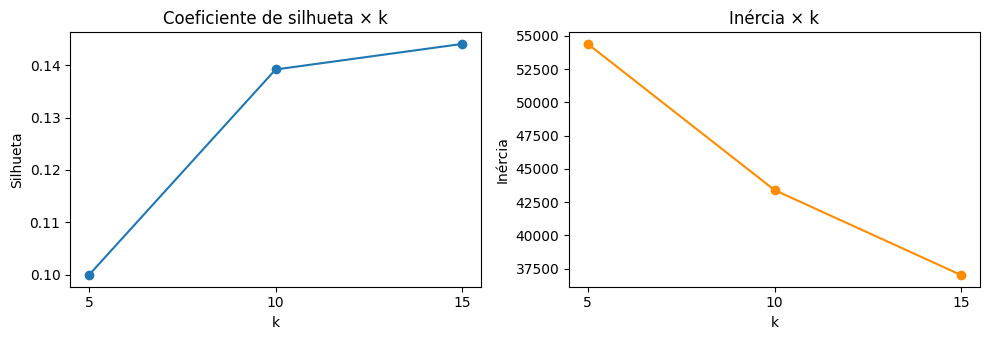

k =  5 | clusters com <= 5 imagens: 0
k = 10 | clusters com <= 5 imagens: 1
k = 15 | clusters com <= 5 imagens: 3


In [6]:
from sklearn.metrics import silhouette_score

silhuetas = {}
inercias = {}
for k in valores_k:
    labels = modelos_kmeans[k].labels_
    silhuetas[k] = silhouette_score(X_tr_s, labels)
    inercias[k] = modelos_kmeans[k].inertia_
    print(f"k = {k:2d} | silhueta = {silhuetas[k]:.4f} | inércia = {inercias[k]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(valores_k, list(silhuetas.values()), marker="o")
axes[0].set_xticks(valores_k)
axes[0].set_xlabel("k"); axes[0].set_ylabel("Silhueta")
axes[0].set_title("Coeficiente de silhueta × k")

axes[1].plot(valores_k, list(inercias.values()), marker="o", color="darkorange")
axes[1].set_xticks(valores_k)
axes[1].set_xlabel("k"); axes[1].set_ylabel("Inércia")
axes[1].set_title("Inércia × k")

plt.tight_layout(); plt.show()

# Clusters muito pequenos (com 5 imagens ou menos)
for k in valores_k:
    tamanhos = np.bincount(modelos_kmeans[k].labels_)
    print(f"k = {k:2d} | clusters com <= 5 imagens: {(tamanhos <= 5).sum()}")

**Resultados:**

| k | Silhueta | Inércia |
|---|---|---|
| 5 | 0,0999 | 54.392,3 |
| 10 | 0,1392 | 43.402,4 |
| 15 | 0,1441 | 37.004,8 |

**Escolha: k = 10.**

- A silhueta sobe bastante de k=5 para k=10 (+0,039), mas de k=10 para k=15 o ganho é muito pequeno (+0,005).
- Com k=15 aparecem **3 clusters quase vazios** (com 1 ou 2 imagens), contra apenas 1 com k=10. Os clusters extras quase não acrescentam estrutura útil.
- Na Tarefa 5, k é o número de atributos novos (distâncias aos centroides). Com k=10 a entrada da rede fica com 74 atributos, contra 79 com k=15, praticamente sem perder qualidade de agrupamento.

Vale ser honesto: **k=15 tem a maior silhueta**, então também seria uma escolha defensável. Além disso, todas as silhuetas são **baixas** (entre 0,10 e 0,14), o que mostra que no espaço de 64 pixels os grupos ficam bastante sobrepostos.

A escolha **não usou os rótulos**: ela se baseou apenas na silhueta, na inércia e no tamanho dos clusters.

In [7]:
k_escolhido = 10
kmeans = modelos_kmeans[k_escolhido]
print("k escolhido:", k_escolhido)

k escolhido: 10


### 2.3 Visualização dos clusters

Para cada cluster mostramos as **10 imagens de treino mais próximas do centroide**. A distância de cada imagem a cada centroide é obtida com `kmeans.transform()`.

Escolhemos 4 clusters para comparar: dois que parecem "puros" e dois misturados.

**Atenção:** a escolha de k já foi feita na etapa anterior, sem rótulos. Aqui os rótulos aparecem **apenas de forma descritiva**, para interpretar o que cada cluster capturou.

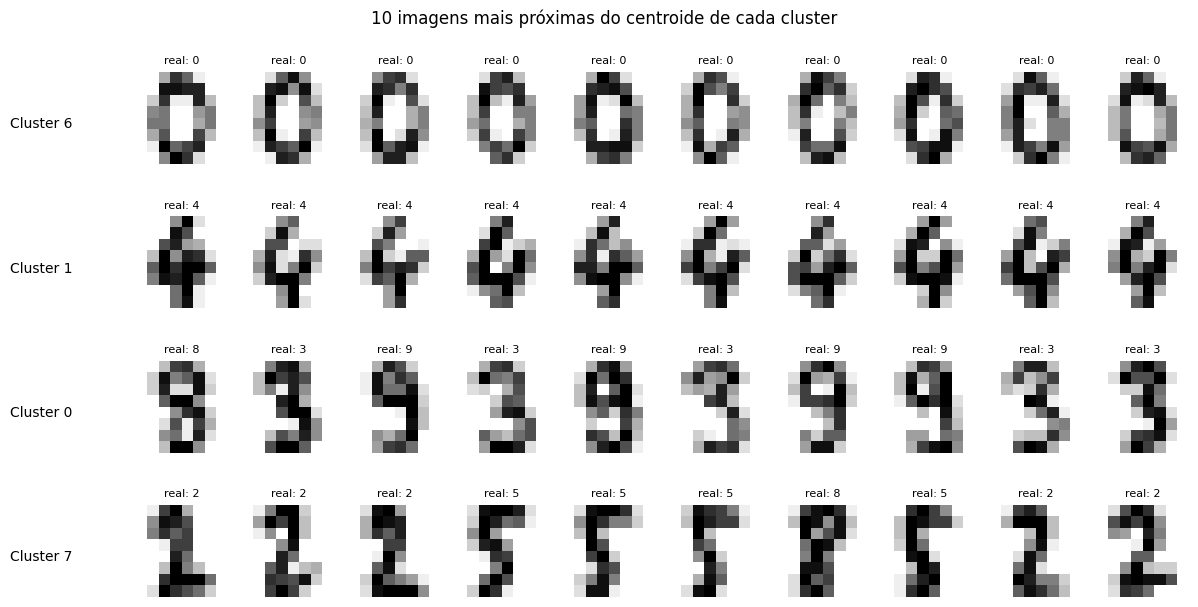

In [8]:
D_tr = kmeans.transform(X_tr_s)        # distâncias de cada imagem de treino aos 10 centroides
labels_tr = kmeans.labels_

clusters_mostrar = [6, 1, 0, 7]

fig, axes = plt.subplots(len(clusters_mostrar), 10, figsize=(12, 1.6 * len(clusters_mostrar)))
for linha, c in enumerate(clusters_mostrar):
    membros = np.where(labels_tr == c)[0]
    mais_proximos = membros[np.argsort(D_tr[membros, c])[:10]]
    for col, i in enumerate(mais_proximos):
        ax = axes[linha, col]
        ax.imshow(X_tr[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"real: {y_tr[i]}", fontsize=8)
        ax.axis("off")
    axes[linha, 0].text(-6, 4, f"Cluster {c}", fontsize=10, va="center", ha="right")
plt.suptitle("10 imagens mais próximas do centroide de cada cluster")
plt.tight_layout(); plt.show()

In [9]:
import pandas as pd

linhas = []
for c in range(k_escolhido):
    reais = y_tr[labels_tr == c]
    contagem = np.bincount(reais, minlength=10)
    dominante = contagem.argmax()
    linhas.append({
        "cluster": c,
        "tamanho": len(reais),
        "dígito dominante": dominante,
        "% do dominante": round(100 * contagem.max() / len(reais), 1),
        "outros dígitos presentes": {d: int(n) for d, n in enumerate(contagem) if n > 0 and d != dominante},
    })
display(pd.DataFrame(linhas))

,cluster,tamanho,dígito dominante,% do dominante,outros dígitos presentes
0,0,286,9,33.2,"{1: 4, 2: 4, 3: 94, 5: 48, 8: 41}"
1,1,104,4,98.1,{5: 2}
2,2,171,1,56.7,"{2: 9, 3: 4, 4: 3, 6: 3, 7: 1, 8: 52, 9: 2}"
3,3,53,2,69.8,{1: 16}
4,4,23,7,60.9,"{4: 6, 9: 3}"
5,5,115,6,97.4,"{5: 2, 8: 1}"
6,6,115,0,98.3,"{5: 1, 6: 1}"
7,7,154,2,40.3,"{3: 12, 4: 1, 5: 57, 7: 4, 8: 16, 9: 2}"
8,8,127,7,74.8,"{2: 1, 3: 7, 4: 4, 5: 6, 8: 1, 9: 13}"
9,9,1,2,100.0,{}


**Por que os clusters não coincidem com as classes?**

O que se observa:
- Alguns clusters são quase **puros**: o cluster 6 tem cerca de 98% de zeros e o cluster 1 cerca de 98% de quatros. Esses dígitos têm um formato bem característico.
- Outros são **misturados**: o cluster 0 junta principalmente **9, 3 e 5**, e o cluster 7 junta **2 e 5**. O cluster 2 mistura 1 e 8.
- Um mesmo dígito pode aparecer **espalhado em vários clusters** (o 2, por exemplo, aparece nos clusters 3 e 7), e existe um cluster com só 1 imagem.

Motivos:
1. **O K-Means não conhece os rótulos.** Ele só minimiza a distância euclidiana entre pixels, então agrupa o que é *visualmente parecido*, e não o que tem o mesmo significado.
2. **Dígitos diferentes podem ter traços parecidos.** Em 8×8 pixels, 3, 5 e 9 compartilham curvas e a parte de baixo, então ficam próximos no espaço de pixels.
3. **O mesmo dígito pode ser escrito de jeitos diferentes** (inclinação, espessura, posição), o que leva ao mesmo dígito em clusters diferentes.
4. **O K-Means assume clusters esféricos e de tamanho parecido**, mas as classes reais têm formas mais complexas. Isso também explica a silhueta baixa (≈ 0,14).

Ou seja, ter k = 10 não garante "um cluster por dígito". Os clusters representam **padrões de escrita**, que podem ou não corresponder a uma classe.

In [10]:
import joblib, json

joblib.dump(kmeans, "kmeans_escolhido.joblib")

resultados_etapa2 = {
    "silhuetas": {str(k): float(silhuetas[k]) for k in valores_k},
    "inercias": {str(k): float(inercias[k]) for k in valores_k},
    "k_escolhido": k_escolhido,
}
with open("etapa2_resultados.json", "w") as f:
    json.dump(resultados_etapa2, f, indent=2)

print("Salvo: kmeans_escolhido.joblib e etapa2_resultados.json")
print(resultados_etapa2)

Salvo: kmeans_escolhido.joblib e etapa2_resultados.json
{'silhuetas': {'5': 0.09987744875077037, '10': 0.1392206688026831, '15': 0.1441147696069928}, 'inercias': {'5': 54392.27740501092, '10': 43402.37336995507, '15': 37004.76893593048}, 'k_escolhido': 10}


---

## Tarefa 3 — Rede neural no Scikit-Learn (Capítulo 9)

### 3.1 Treinamento do MLPClassifier

Configuração pedida no enunciado:
- **Duas camadas ocultas** com 64 e 32 neurônios: `hidden_layer_sizes=(64, 32)`;
- ativação **ReLU**;
- `random_state=42`;
- **até 200 épocas**: `max_iter=200`.

Os demais parâmetros ficam no padrão do scikit-learn: otimizador **Adam**, taxa de aprendizado 0,001, regularização L2 `alpha=0.0001` e lotes de até 200 exemplos.

A rede é treinada com os **64 atributos padronizados do treino** (`X_tr_s`). Medimos o **tempo de treino** e usamos a **validação** para conferir o desempenho. O teste só é usado na avaliação final.

In [11]:
import time
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

mlp_sk = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                       max_iter=200, random_state=SEED)

# Registra os avisos (como ConvergenceWarning) para relatar, sem esconder
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    inicio = time.perf_counter()
    mlp_sk.fit(X_tr_s, y_tr)
    tempo_sk = time.perf_counter() - inicio

print(f"Tempo de treino: {tempo_sk:.3f} s")
print(f"Épocas executadas: {mlp_sk.n_iter_} (máximo 200)")
print(f"Perda final no treino: {mlp_sk.loss_curve_[-1]:.4f}")
print("Avisos durante o treino:", [str(a.message) for a in avisos] or "nenhum")

# Conferência na VALIDAÇÃO (não usa o teste)
acc_val_sk = accuracy_score(y_val, mlp_sk.predict(X_val_s))
print(f"Acurácia na validação: {acc_val_sk:.4f}")

Tempo de treino: 1.150 s
Épocas executadas: 120 (máximo 200)
Perda final no treino: 0.0037
Avisos durante o treino: nenhum
Acurácia na validação: 0.9688


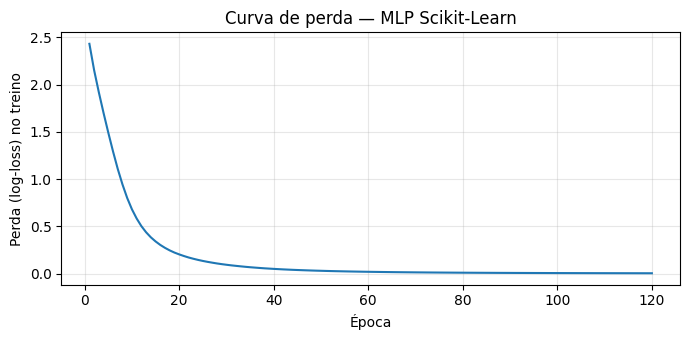

In [12]:
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(mlp_sk.loss_curve_) + 1), mlp_sk.loss_curve_)
plt.xlabel("Época"); plt.ylabel("Perda (log-loss) no treino")
plt.title("Curva de perda — MLP Scikit-Learn")
plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Observações:**
- O treino **parou na época 120**, antes do limite de 200. O scikit-learn interrompe o treino quando a perda deixa de melhorar mais que `tol=1e-4` por 10 épocas seguidas. Por isso **não apareceu `ConvergenceWarning`**: o modelo convergiu.
- A perda cai rápido nas primeiras épocas e depois se estabiliza perto de zero, o que indica que a rede aprendeu bem o conjunto de treino.
- A acurácia na validação ficou em **96,9%**, sinal de que o modelo generaliza bem e não está apenas decorando o treino.

### 3.2 Avaliação no teste e análise de erros

Agora o modelo é avaliado **uma única vez no conjunto de teste**, que não foi usado em nenhuma decisão até aqui.

Métricas:
- **Acurácia**: proporção de imagens classificadas corretamente;
- **F1 macro**: média do F1 de cada classe, dando o mesmo peso a todos os dígitos;
- **Matriz de confusão**: mostra quais dígitos são confundidos com quais.

Acurácia (teste): 0.9611
F1 macro (teste): 0.9607
Erros: 14 de 360


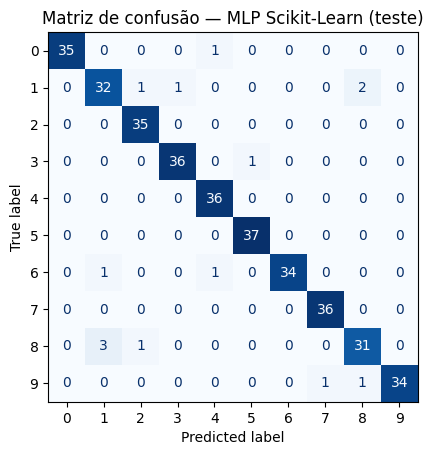

In [13]:
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

y_pred_sk = mlp_sk.predict(X_te_s)
acc_sk = accuracy_score(y_te, y_pred_sk)
f1_sk = f1_score(y_te, y_pred_sk, average="macro")

print(f"Acurácia (teste): {acc_sk:.4f}")
print(f"F1 macro (teste): {f1_sk:.4f}")
print(f"Erros: {(y_pred_sk != y_te).sum()} de {len(y_te)}")

cm_sk = confusion_matrix(y_te, y_pred_sk)
ConfusionMatrixDisplay(cm_sk, display_labels=range(10)).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão — MLP Scikit-Learn (teste)")
plt.show()

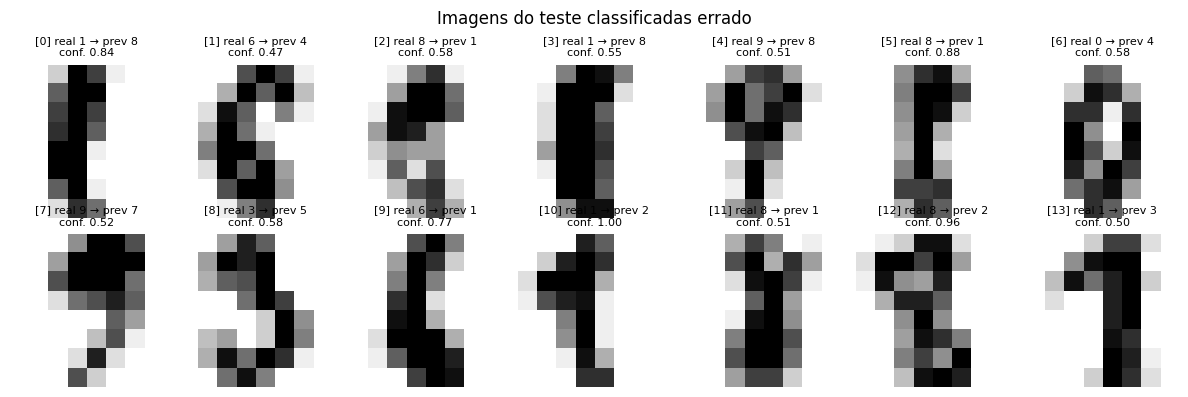

In [14]:
proba_sk = mlp_sk.predict_proba(X_te_s)
erros = np.where(y_pred_sk != y_te)[0]

fig, axes = plt.subplots(2, 7, figsize=(12, 4))
for j, ax in enumerate(axes.flat):
    if j < len(erros):
        i = erros[j]
        ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"[{j}] real {y_te[i]} → prev {y_pred_sk[i]}\nconf. {proba_sk[i].max():.2f}", fontsize=8)
    ax.axis("off")
plt.suptitle("Imagens do teste classificadas errado")
plt.tight_layout(); plt.show()

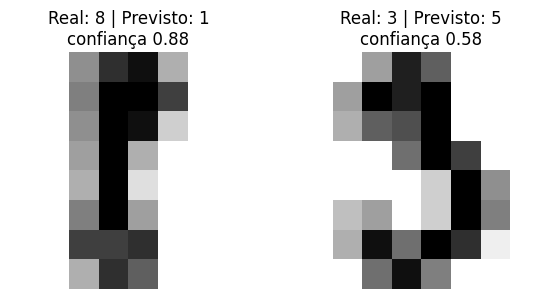

In [15]:
analisar = [5, 8]   # posições na lista de erros acima

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, j in zip(axes, analisar):
    i = erros[j]
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Real: {y_te[i]} | Previsto: {y_pred_sk[i]}\nconfiança {proba_sk[i].max():.2f}")
    ax.axis("off")
plt.tight_layout(); plt.show()

**Resultados no teste:** acurácia de **96,1%** e F1 macro de **0,961** (14 erros em 360 imagens).

**Padrão na matriz de confusão:** a confusão mais frequente é entre **8 e 1**: 3 imagens de 8 foram previstas como 1 e 2 imagens de 1 foram previstas como 8. Os outros erros aparecem de forma isolada.

**Erro 1 — real 8, previsto 1 (confiança 0,88):**
Este 8 foi escrito **estreito e vertical**, e as duas "bolinhas" quase não aparecem: em 8×8 pixels viram praticamente uma coluna escura no centro, que é justamente o formato de um 1 grosso. A rede errou com confiança alta porque a imagem realmente se parece mais com os 1 do treino.

**Erro 2 — real 3, previsto 5 (confiança 0,58):**
A parte de baixo do 3 e do 5 é a mesma curva. Neste exemplo, a parte de cima do 3 ficou com um traço mais reto e deslocado para a esquerda, parecido com a "barriga" superior de um 5. A confiança baixa (0,58) mostra que a rede ficou em dúvida entre as duas classes.

**Conclusão:** os erros vêm principalmente da **baixa resolução (8×8)** e da **escrita ambígua**: com tão poucos pixels, traços diferentes acabam ficando parecidos.

In [16]:
resultados_etapa3 = {"acuracia": float(acc_sk), "f1_macro": float(f1_sk), "tempo_treino_s": float(tempo_sk)}
with open("etapa3_resultados.json", "w") as f:
    json.dump(resultados_etapa3, f, indent=2)
print(resultados_etapa3)

{'acuracia': 0.9611111111111111, 'f1_macro': 0.9607348454039307, 'tempo_treino_s': 1.150363617000039}


### 3.3 Papel das camadas ocultas, da função de ativação e da aprendizagem por gradientes

**Camadas ocultas**
São as camadas entre a entrada (64 pixels) e a saída (10 classes). Cada uma transforma os dados em uma **representação intermediária**. A primeira camada (64 neurônios) tende a detectar padrões simples, como traços e regiões escuras. A segunda (32 neurônios) combina esses padrões em formas mais complexas, como curvas e laços, que ajudam a separar os dígitos. Com isso a rede aprende sozinha quais características importam, sem que a gente precise defini-las.

**Função de ativação (ReLU)**
A ReLU é `f(x) = max(0, x)`: mantém os valores positivos e zera os negativos. O papel dela é introduzir **não linearidade**. Sem ativação, empilhar camadas seria o mesmo que ter **uma única transformação linear**, e a rede não conseguiria aprender fronteiras complexas entre as classes. A ReLU também é simples de calcular e ajuda a evitar que os gradientes fiquem muito pequenos.

**Aprendizagem por gradientes**
O treino busca **minimizar a função de perda** (aqui, a entropia cruzada, que mede o quanto as previsões erram). A cada lote de dados:
1. a rede faz as previsões (*forward*);
2. a perda é calculada;
3. a **retropropagação** (*backpropagation*) calcula o gradiente da perda em relação a cada peso;
4. os pesos são ajustados **na direção oposta ao gradiente** (gradiente negativo), que é a direção em que a perda diminui.

O otimizador usado, o **Adam**, é uma variação do gradiente descendente que adapta o tamanho do passo para cada peso. A curva de perda da seção 3.1 mostra esse processo: a perda cai a cada época até se estabilizar.

---

## Tarefa 4 — Rede neural com PyTorch (Capítulo 10)

### 4.1 Implementação e treino da MLP

Mesma arquitetura da Tarefa 3: `Linear(64,64) → ReLU → Linear(64,32) → ReLU → Linear(32,10)`.

- **Perda:** `CrossEntropyLoss`. Ela já aplica o softmax internamente, então a última camada devolve os *logits* (sem softmax no fim).
- **Otimizador:** `Adam`.
- **Dados:** `DataLoader` com `shuffle=True` no treino e um `torch.Generator` com semente fixa, para ser reprodutível.

**Hiperparâmetros e justificativa:** `lr = 0.001`, `batch_size = 200`, `epochs = 200`, sem *early stopping*. São os mesmos valores padrão do `MLPClassifier` da Tarefa 3 (Adam com taxa 0,001, lotes de até 200 e até 200 épocas), para que a comparação seja justa. **Esses mesmos valores serão usados na Tarefa 5.**

O ciclo de treino é escrito de forma explícita, na ordem: **zerar gradientes → forward → perda → backward → optimizer.step**. Ao fim de cada época a rede é avaliada na **validação** (`model.eval()` + `torch.no_grad()`), e guardamos as perdas de treino e de validação.

In [17]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

LR = 1e-3
BATCH_SIZE = 200
EPOCHS = 200

class MLP(nn.Module):
    def __init__(self, n_entrada):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_entrada, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 10)            # logits (sem softmax)
        )

    def forward(self, x):
        return self.rede(x)


def rodar_mlp(Xtr, Xval, seed=SEED):
    """Treina a MLP com os dados de treino e valida a cada época. Não usa o teste."""
    torch.manual_seed(seed)
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
    Xval_t = torch.tensor(Xval, dtype=torch.float32)
    ytr_t = torch.tensor(y_tr, dtype=torch.long)
    yval_t = torch.tensor(y_val, dtype=torch.long)

    g = torch.Generator().manual_seed(seed)
    loader_tr = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=BATCH_SIZE,
                           shuffle=True, generator=g)

    model = MLP(Xtr.shape[1])
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    hist_tr, hist_val, acc_val = [], [], []
    inicio = time.perf_counter()
    for epoca in range(EPOCHS):
        model.train()
        soma, n = 0.0, 0
        for xb, yb in loader_tr:
            optimizer.zero_grad()            # 1. zerar gradientes
            logits = model(xb)               # 2. forward
            loss = criterion(logits, yb)     # 3. perda
            loss.backward()                  # 4. backward (retropropagação)
            optimizer.step()                 # 5. atualizar os pesos
            soma += loss.item() * len(xb); n += len(xb)
        hist_tr.append(soma / n)

        model.eval()                         # validação separada
        with torch.no_grad():
            logits_val = model(Xval_t)
            hist_val.append(criterion(logits_val, yval_t).item())
            acc_val.append((logits_val.argmax(1) == yval_t).float().mean().item())
    tempo = time.perf_counter() - inicio
    return model, hist_tr, hist_val, acc_val, tempo


def prever(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32)).argmax(1).numpy()

In [18]:
model_pt, hist_tr_pt, hist_val_pt, acc_val_pt, tempo_pt = rodar_mlp(X_tr_s, X_val_s)

print(f"Tempo de treino: {tempo_pt:.2f} s ({EPOCHS} épocas, incluindo a validação a cada época)")
print(f"Perda final - treino: {hist_tr_pt[-1]:.4f} | validação: {hist_val_pt[-1]:.4f}")
print(f"Menor perda de validação: {min(hist_val_pt):.4f} na época {int(np.argmin(hist_val_pt)) + 1}")
print(f"Acurácia na validação (última época): {acc_val_pt[-1]:.4f}")

Tempo de treino: 2.83 s (200 épocas, incluindo a validação a cada época)
Perda final - treino: 0.0010 | validação: 0.0912
Menor perda de validação: 0.0910 na época 172
Acurácia na validação (última época): 0.9722


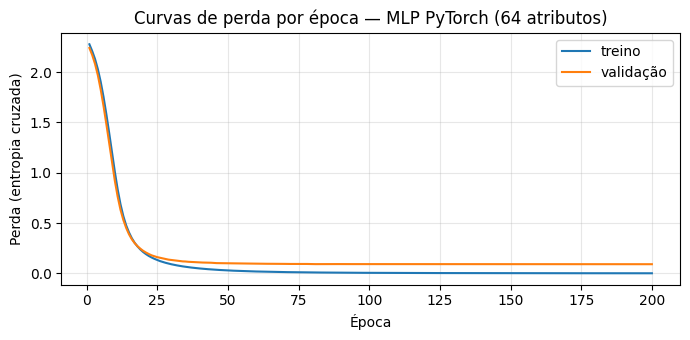

In [19]:
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, EPOCHS + 1), hist_tr_pt, label="treino")
plt.plot(range(1, EPOCHS + 1), hist_val_pt, label="validação")
plt.xlabel("Época"); plt.ylabel("Perda (entropia cruzada)")
plt.title("Curvas de perda por época — MLP PyTorch (64 atributos)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 4.2 Avaliação no teste

Assim como na Tarefa 3, o teste é usado **uma única vez**, depois do treino.

Acurácia (teste): 0.9694
F1 macro (teste): 0.9689
Erros: 11 de 360


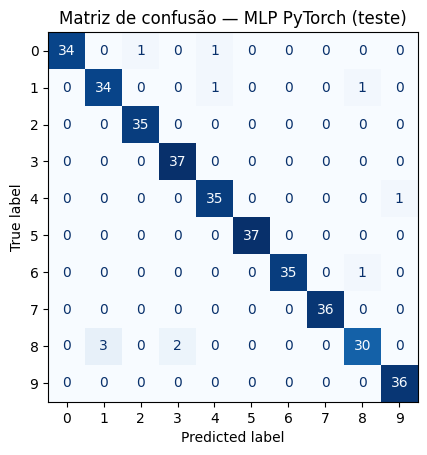

Comparação com o Scikit-Learn:


,Modelo,Acurácia (teste),F1 macro (teste),Tempo de treino (s)
0,MLP Scikit-Learn,0.9611,0.9607,1.15
1,MLP PyTorch,0.9694,0.9689,2.83


In [20]:
y_pred_pt = prever(model_pt, X_te_s)
acc_pt = accuracy_score(y_te, y_pred_pt)
f1_pt = f1_score(y_te, y_pred_pt, average="macro")

print(f"Acurácia (teste): {acc_pt:.4f}")
print(f"F1 macro (teste): {f1_pt:.4f}")
print(f"Erros: {(y_pred_pt != y_te).sum()} de {len(y_te)}")

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_pt), display_labels=range(10)).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão — MLP PyTorch (teste)")
plt.show()

resultados_etapa4 = {"acuracia": float(acc_pt), "f1_macro": float(f1_pt), "tempo_treino_s": float(tempo_pt)}
with open("etapa4_resultados.json", "w") as f:
    json.dump(resultados_etapa4, f, indent=2)

print("Comparação com o Scikit-Learn:")
display(pd.DataFrame({
    "Modelo": ["MLP Scikit-Learn", "MLP PyTorch"],
    "Acurácia (teste)": [round(acc_sk, 4), round(acc_pt, 4)],
    "F1 macro (teste)": [round(f1_sk, 4), round(f1_pt, 4)],
    "Tempo de treino (s)": [round(tempo_sk, 2), round(tempo_pt, 2)],
}))

**Comparação com o Scikit-Learn (SEED = 42):**

| Modelo | Acurácia | F1 macro | Erros (de 360) | Tempo de treino |
|---|---|---|---|---|
| MLP Scikit-Learn | 0,9611 | 0,9607 | 14 | 1,15 s |
| MLP PyTorch | 0,9694 | 0,9689 | 11 | 2,83 s |

- O PyTorch acertou **3 imagens a mais** (cerca de 0,8 ponto). É uma diferença pequena: com 360 imagens no teste, cada imagem vale 0,28 ponto.
- As diferenças são esperadas, porque as implementações não são idênticas: o scikit-learn **parou na época 120** (critério de tolerância), enquanto o PyTorch rodou as **200 épocas completas**; o scikit-learn usa **regularização L2** (`alpha=1e-4`) por padrão e o PyTorch não; e a **inicialização dos pesos** é diferente nas duas bibliotecas.
- O PyTorch foi **mais lento** porque o laço de treino é escrito em Python, roda 200 épocas e ainda avalia a validação a cada época. O scikit-learn faz tudo internamente e parou antes.
- As curvas de perda mostram que a perda de validação caiu junto com a de treino e se estabilizou (mínimo de 0,0910 na época 172 e 0,0912 no final), ou seja, **não houve overfitting forte** mesmo sem early stopping.
- A confusão mais frequente continua sendo a do dígito **8**, previsto como 1 ou 3, o mesmo padrão visto na Tarefa 3.

---

## Tarefa 5 — Experimento integrador e interpretação

### 5.1 Atributos do agrupamento

Carregamos o K-Means salvo na Tarefa 2 (**sem retreinar e sem recalibrar**) e usamos `transform()` para obter, para cada imagem, as **k = 10 distâncias aos centroides**. Essas distâncias são concatenadas aos 64 pixels, formando **74 atributos**.

**Escala das distâncias:** os pixels já estão padronizados, mas as distâncias não (elas têm valores bem maiores). Para que nenhum grupo de atributos domine o treino, as **10 colunas novas são padronizadas com um segundo `StandardScaler`, ajustado apenas no treino** e aplicado sem reajuste à validação e ao teste.

In [21]:
kmeans_carregado = joblib.load("kmeans_escolhido.joblib")   # mesmo modelo da Tarefa 2
k = kmeans_carregado.n_clusters

D_tr  = kmeans_carregado.transform(X_tr_s)
D_val = kmeans_carregado.transform(X_val_s)
D_te  = kmeans_carregado.transform(X_te_s)
print(f"Distâncias (antes da padronização): média {D_tr.mean():.2f}, mín {D_tr.min():.2f}, máx {D_tr.max():.2f}")

scaler_dist = StandardScaler().fit(D_tr)          # ajuste SOMENTE no treino
D_tr_s, D_val_s, D_te_s = scaler_dist.transform(D_tr), scaler_dist.transform(D_val), scaler_dist.transform(D_te)

X_tr_ext  = np.hstack([X_tr_s,  D_tr_s])
X_val_ext = np.hstack([X_val_s, D_val_s])
X_te_ext  = np.hstack([X_te_s,  D_te_s])
print("Formas com 64 + k atributos:", X_tr_ext.shape, X_val_ext.shape, X_te_ext.shape)

Distâncias (antes da padronização): média 13.27, mín 0.00, máx 62.07
Formas com 64 + k atributos: (1149, 74) (288, 74) (360, 74)


Tempo de treino: 2.68 s
Perda final - treino: 0.0010 | validação: 0.0620
Acurácia na validação (última época): 0.9757


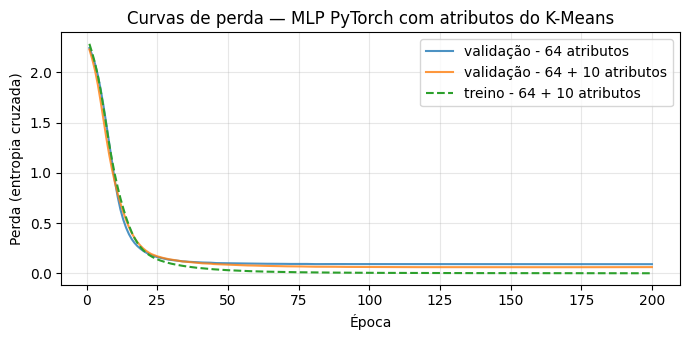

In [22]:
# Mesma arquitetura (só a 1ª camada muda para 64 + k entradas), mesmos hiperparâmetros e semente
model_ext, hist_tr_ext, hist_val_ext, acc_val_ext, tempo_ext = rodar_mlp(X_tr_ext, X_val_ext)

print(f"Tempo de treino: {tempo_ext:.2f} s")
print(f"Perda final - treino: {hist_tr_ext[-1]:.4f} | validação: {hist_val_ext[-1]:.4f}")
print(f"Acurácia na validação (última época): {acc_val_ext[-1]:.4f}")

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, EPOCHS + 1), hist_val_pt, label="validação - 64 atributos", alpha=0.8)
plt.plot(range(1, EPOCHS + 1), hist_val_ext, label=f"validação - 64 + {k} atributos", alpha=0.8)
plt.plot(range(1, EPOCHS + 1), hist_tr_ext, label=f"treino - 64 + {k} atributos", linestyle="--")
plt.xlabel("Época"); plt.ylabel("Perda (entropia cruzada)")
plt.title("Curvas de perda — MLP PyTorch com atributos do K-Means")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Acurácia (teste): 0.9778
F1 macro (teste): 0.9775
Erros: 8 de 360


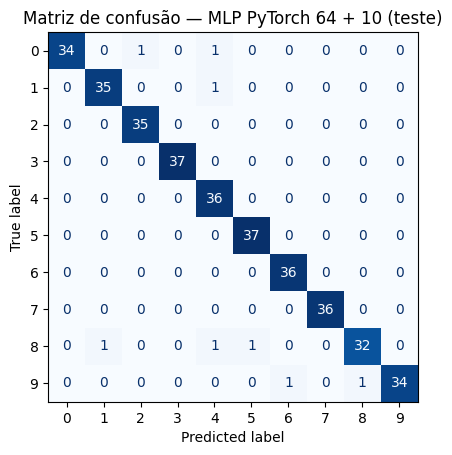

In [23]:
# Avaliação no teste (uma única vez)
y_pred_ext = prever(model_ext, X_te_ext)
acc_ext = accuracy_score(y_te, y_pred_ext)
f1_ext = f1_score(y_te, y_pred_ext, average="macro")
print(f"Acurácia (teste): {acc_ext:.4f}")
print(f"F1 macro (teste): {f1_ext:.4f}")
print(f"Erros: {(y_pred_ext != y_te).sum()} de {len(y_te)}")

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_ext), display_labels=range(10)).plot(cmap="Blues", colorbar=False)
plt.title(f"Matriz de confusão — MLP PyTorch 64 + {k} (teste)")
plt.show()

resultados_etapa5 = {"acuracia": float(acc_ext), "f1_macro": float(f1_ext), "tempo_treino_s": float(tempo_ext), "k": int(k)}
with open("etapa5_resultados.json", "w") as f:
    json.dump(resultados_etapa5, f, indent=2)

### 5.2 Comparação dos três modelos (SEED = 42)

In [24]:
tabela_final = pd.DataFrame({
    "Modelo": ["MLP Scikit-Learn (64 atributos)", "MLP PyTorch (64 atributos)", f"MLP PyTorch (64 + {k})"],
    "Acurácia (teste)": [acc_sk, acc_pt, acc_ext],
    "F1 macro (teste)": [f1_sk, f1_pt, f1_ext],
    "Erros (de 360)": [(y_pred_sk != y_te).sum(), (y_pred_pt != y_te).sum(), (y_pred_ext != y_te).sum()],
    "Tempo de treino (s)": [tempo_sk, tempo_pt, tempo_ext],
}).round(4)
display(tabela_final)

,Modelo,Acurácia (teste),F1 macro (teste),Erros (de 360),Tempo de treino (s)
0,MLP Scikit-Learn (64 atributos),0.9611,0.9607,14,1.1504
1,MLP PyTorch (64 atributos),0.9694,0.9689,11,2.8329
2,MLP PyTorch (64 + 10),0.9778,0.9775,8,2.6753


### 5.3 Repetição com outras sementes (evidência extra)

Uma única semente pode dar um resultado favorável ou desfavorável por acaso. Por isso repetimos os dois modelos PyTorch com **5 sementes** (mudando só a inicialização dos pesos e a ordem dos lotes; as divisões dos dados continuam as mesmas). O teste é usado apenas para medir, **nada é ajustado** com base nele. A tabela principal continua sendo a de `SEED = 42`.

In [25]:
sementes = [0, 1, 2, 3, 42]
acc_64, acc_64k = [], []
for s in sementes:
    m64, *_ = rodar_mlp(X_tr_s, X_val_s, seed=s)
    mext, *_ = rodar_mlp(X_tr_ext, X_val_ext, seed=s)
    acc_64.append(accuracy_score(y_te, prever(m64, X_te_s)))
    acc_64k.append(accuracy_score(y_te, prever(mext, X_te_ext)))
    print(f"semente {s:2d} | 64: {acc_64[-1]:.4f} | 64+k: {acc_64k[-1]:.4f}")

print(f"64 atributos:   média {np.mean(acc_64):.4f} ± {np.std(acc_64):.4f}")
print(f"64+k atributos: média {np.mean(acc_64k):.4f} ± {np.std(acc_64k):.4f}")
dif = np.array(acc_64k) - np.array(acc_64)
print(f"Diferença (64+k - 64) por semente: {np.round(dif, 4).tolist()}")

semente  0 | 64: 0.9639 | 64+k: 0.9722
semente  1 | 64: 0.9778 | 64+k: 0.9889
semente  2 | 64: 0.9750 | 64+k: 0.9778
semente  3 | 64: 0.9750 | 64+k: 0.9750
semente 42 | 64: 0.9694 | 64+k: 0.9778
64 atributos:   média 0.9722 ± 0.0050
64+k atributos: média 0.9783 ± 0.0057
Diferença (64+k - 64) por semente: [0.0083, 0.0111, 0.0028, 0.0, 0.0083]


In [26]:
# Onde os erros mudaram? Erros no teste por dígito real (SEED = 42)
erros_por_classe = pd.DataFrame({
    "Scikit-Learn (64)": np.bincount(y_te[y_pred_sk != y_te], minlength=10),
    "PyTorch (64)": np.bincount(y_te[y_pred_pt != y_te], minlength=10),
    f"PyTorch (64 + {k})": np.bincount(y_te[y_pred_ext != y_te], minlength=10),
})
erros_por_classe.index.name = "dígito real"
print(erros_por_classe.to_string())
print()
print("Pares (real -> previsto) errados pelo PyTorch 64:     ", sorted(zip(y_te[y_pred_pt != y_te].tolist(), y_pred_pt[y_pred_pt != y_te].tolist())))
print("Pares (real -> previsto) errados pelo PyTorch 64 + k: ", sorted(zip(y_te[y_pred_ext != y_te].tolist(), y_pred_ext[y_pred_ext != y_te].tolist())))

             Scikit-Learn (64)  PyTorch (64)  PyTorch (64 + 10)
dígito real                                                    
0                            1             2                  2
1                            4             2                  1
2                            0             0                  0
3                            1             0                  0
4                            0             1                  0
5                            0             0                  0
6                            2             1                  0
7                            0             0                  0
8                            4             5                  3
9                            2             0                  2

Pares (real -> previsto) errados pelo PyTorch 64:      [(0, 2), (0, 4), (1, 4), (1, 8), (4, 9), (6, 8), (8, 1), (8, 1), (8, 1), (8, 3), (8, 3)]
Pares (real -> previsto) errados pelo PyTorch 64 + k:  [(0, 2), (0, 4), (1, 4), (8, 1),

### 5.4 Discussão: os atributos do agrupamento ajudaram?

**Resultado principal (SEED = 42):**

| Modelo | Acurácia (teste) | F1 macro (teste) | Erros (de 360) | Tempo de treino |
|---|---|---|---|---|
| MLP Scikit-Learn (64 atributos) | 0,9611 | 0,9607 | 14 | 1,15 s |
| MLP PyTorch (64 atributos) | 0,9694 | 0,9689 | 11 | 2,83 s |
| MLP PyTorch (64 + 10) | 0,9778 | 0,9775 | 8 | 2,68 s |

Com as distâncias aos centroides, a MLP PyTorch caiu de **11 para 8 erros** (+0,8 ponto de acurácia). O tempo de treino ficou praticamente igual, porque só a primeira camada ganhou 10 entradas.

**Esse ganho é real ou é ruído?** Com 360 imagens no teste, 3 imagens de diferença é pouco, e uma única semente não basta para concluir. Por isso olhamos outras evidências:

1. **Outras sementes:** em 5 sementes, o modelo 64 + k foi **melhor em 4 e empatou em 1, sem nenhuma piora**. A média passou de **0,9722 ± 0,0050** para **0,9783 ± 0,0057**, um ganho médio de cerca de 0,6 ponto (cerca de 2 imagens).
2. **Validação:** sem olhar o teste, a perda de validação final caiu de **0,0912 para 0,0620** e a acurácia na validação subiu de **0,9722 para 0,9757**.
3. **Onde os erros mudaram:** o modelo com distâncias corrigiu parte das confusões do dígito 8 com 1 e 3 (o 8 passou de 5 para 3 erros), mas criou outros erros isolados (por exemplo 9→6 e 9→8). Ou seja, ele não é melhor em tudo.

**Interpretação:** os atributos do K-Means **ajudaram um pouco, de forma consistente, mas o ganho é pequeno** (da ordem de 1 a 3 imagens) e fica perto da variação natural entre sementes. Uma explicação plausível é que as distâncias resumem a **posição global da imagem em relação a 10 "protótipos de escrita"**, uma informação que a rede teria que aprender sozinha a partir dos pixels. Isso facilita separar formas parecidas, como o 8 estreito que parece um 1.

Ao mesmo tempo, o ganho não poderia ser grande: o K-Means foi treinado **sem rótulos** e as distâncias são calculadas **a partir dos mesmos 64 pixels**, então a informação nova é limitada. Como vimos na Tarefa 2, os clusters também misturam dígitos (por exemplo 3, 5 e 9 no mesmo grupo).

## Conclusão

- **Pergunta central:** sim, as distâncias aos centroides do K-Means **ajudaram levemente** a MLP: de 96,94% para 97,78% de acurácia com `SEED = 42`, e ganho médio de cerca de 0,6 ponto em 5 sementes, sem piora em nenhuma delas.
- **Ressalvas:** o teste tem só 360 imagens, então o ganho equivale a poucas imagens; as divisões dos dados foram as mesmas em todas as sementes; e foi testado apenas k = 10. Para afirmar com mais segurança seria preciso validação cruzada ou um conjunto de teste maior.
- **Cuidados metodológicos:** os escalonadores e o K-Means foram ajustados só no treino; o k foi escolhido sem rótulos; o K-Means não foi retreinado na Tarefa 5; e o teste foi usado apenas para a avaliação final, sem ajustar nenhum hiperparâmetro.